In [1]:
import pandas as pd
import numpy as np

file_path = "Retail_Inventory_Supply_Chain_Cleaned_Data.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Dataset shape: (35000, 25)
Number of rows: 35000
Number of columns: 25


In [2]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Column Names:
['Record_ID', 'Order_ID', 'Order_Date', 'Product_ID', 'Product_Name', 'Category', 'Subcategory', 'Supplier_ID', 'Supplier_Name', 'Warehouse_ID', 'Warehouse_Location', 'Stock_On_Hand', 'Reorder_Level', 'Order_Quantity', 'Units_Sold', 'Unit_Cost_INR', 'Unit_Price_INR', 'Inventory_Value_INR', 'Lead_Time_Days', 'Shipping_Cost_INR', 'Delivery_Status', 'Returned_Units', 'Demand_Forecast_Units', 'Sales_Channel', 'Payment_Terms']

Data Types:
Record_ID                           str
Order_ID                            str
Order_Date               datetime64[us]
Product_ID                          str
Product_Name                        str
Category                            str
Subcategory                         str
Supplier_ID                         str
Supplier_Name                       str
Warehouse_ID                        str
Warehouse_Location                  str
Stock_On_Hand                   float64
Reorder_Level                     int64
Order_Quantity             

,Record_ID,Order_ID,Order_Date,Product_ID,Product_Name,Category,Subcategory,Supplier_ID,Supplier_Name,Warehouse_ID,...,Unit_Cost_INR,Unit_Price_INR,Inventory_Value_INR,Lead_Time_Days,Shipping_Cost_INR,Delivery_Status,Returned_Units,Demand_Forecast_Units,Sales_Channel,Payment_Terms
0,R001713,ORD298598,2025-07-13,P1010,Backpack,Electronics,Bags,S06,Apex Retail Supply,W03,...,700,1499,123200,11,774.95,On Time,0.0,74.0,Wholesale,Net 15
1,R006053,ORD974000,2025-07-29,P1025,Garden Gloves,Electronics,Tools,S08,UrbanCart Partners,W05,...,110,249,14410,9,825.95,Delayed,0.0,125.0,Website,COD
2,R007919,ORD437677,2025-10-21,P1021,Hair Dryer,Electronics,Personal Care,S08,UrbanCart Partners,W04,...,1250,2299,318750,9,150.71,On Time,0.0,52.0,Wholesale,COD
3,R008771,ORD423091,2025-12-09,P1025,Garden Gloves,Electronics,Tools,S05,Evergreen Distributors,W01,...,110,249,12980,11,265.38,On Time,1.0,39.0,Mobile App,Net 30
4,R009636,ORD555615,2025-08-15,P1004,LED Desk Lamp,Electronics,Lighting,S05,Evergreen Distributors,W01,...,520,999,84760,15,665.06,On Time,0.0,65.0,Retail Store,Prepaid


In [3]:
missing_values = df.isnull().sum()

print("Columns with Missing Values:")
print(missing_values[missing_values > 0].sort_values(ascending=False))

print("\nTotal Missing Cells:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Columns with Missing Values:
Demand_Forecast_Units    67
Order_Quantity           66
Stock_On_Hand            64
Returned_Units           57
Warehouse_Location       56
Supplier_Name            53
Shipping_Cost_INR        53
dtype: int64

Total Missing Cells: 416
Duplicate Rows: 0


In [4]:
# Recover missing supplier names using Supplier_ID
supplier_lookup = (
    df.dropna(subset=["Supplier_ID", "Supplier_Name"])
      .drop_duplicates(subset=["Supplier_ID"])
      .set_index("Supplier_ID")["Supplier_Name"]
)

df["Supplier_Name"] = df["Supplier_Name"].fillna(
    df["Supplier_ID"].map(supplier_lookup)
)

# Recover missing warehouse locations using Warehouse_ID
warehouse_lookup = (
    df.dropna(subset=["Warehouse_ID", "Warehouse_Location"])
      .drop_duplicates(subset=["Warehouse_ID"])
      .set_index("Warehouse_ID")["Warehouse_Location"]
)

df["Warehouse_Location"] = df["Warehouse_Location"].fillna(
    df["Warehouse_ID"].map(warehouse_lookup)
)

print("Missing Supplier Names:", df["Supplier_Name"].isna().sum())
print("Missing Warehouse Locations:", df["Warehouse_Location"].isna().sum())

Missing Supplier Names: 0
Missing Warehouse Locations: 0


In [7]:
# Keep unknown numeric values as missing (NaN)
# They will be handled appropriately during analysis.

print("Missing Numeric Values Retained:")
print(df[[
    "Stock_On_Hand",
    "Order_Quantity",
    "Shipping_Cost_INR",
    "Returned_Units",
    "Demand_Forecast_Units"
]].isnull().sum())

print("\nTotal Missing Numeric Cells:",
      df[[
          "Stock_On_Hand",
          "Order_Quantity",
          "Shipping_Cost_INR",
          "Returned_Units",
          "Demand_Forecast_Units"
      ]].isnull().sum().sum())

Missing Numeric Values Retained:
Stock_On_Hand            64
Order_Quantity           66
Shipping_Cost_INR        53
Returned_Units           57
Demand_Forecast_Units    67
dtype: int64

Total Missing Numeric Cells: 307


In [8]:
# Standardize text formatting
df["Category"] = df["Category"].str.strip().str.title()
df["Delivery_Status"] = df["Delivery_Status"].str.strip().str.title()

print("Category Values:")
print(sorted(df["Category"].dropna().unique()))

print("\nDelivery Status Values:")
print(sorted(df["Delivery_Status"].dropna().unique()))

Category Values:
['Beauty', 'Electronics', 'Fashion', 'Furniture', 'Garden', 'Grocery', 'Home & Living', 'Pet Supplies', 'Sports', 'Stationery', 'Toys']

Delivery Status Values:
['Cancelled', 'Delayed', 'In Transit', 'On Time']


In [9]:
print("Final Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values by Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal Missing Cells:", df.isnull().sum().sum())

Final Dataset Shape: (35000, 25)

Duplicate Rows: 0

Missing Values by Column:
Stock_On_Hand            64
Order_Quantity           66
Shipping_Cost_INR        53
Returned_Units           57
Demand_Forecast_Units    67
dtype: int64

Total Missing Cells: 307


In [10]:
output_file = "Retail_Inventory_Supply_Chain_Cleaned.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")
print("File name:", output_file)
print("Final shape:", df.shape)

Cleaned dataset saved successfully!
File name: Retail_Inventory_Supply_Chain_Cleaned.csv
Final shape: (35000, 25)


In [12]:
# Summary statistics for key business metrics
key_columns = [
    "Units_Sold",
    "Unit_Cost_INR",
    "Unit_Price_INR",
    "Inventory_Value_INR",
    "Stock_On_Hand",
    "Order_Quantity",
    "Reorder_Level",
    "Lead_Time_Days",
    "Shipping_Cost_INR",
    "Returned_Units",
    "Demand_Forecast_Units"
]

display(df[key_columns].describe().round(2))

,Units_Sold,Unit_Cost_INR,Unit_Price_INR,Inventory_Value_INR,Stock_On_Hand,Order_Quantity,Reorder_Level,Lead_Time_Days,Shipping_Cost_INR,Returned_Units,Demand_Forecast_Units
count,35000.00,35000.00,35000.00,35000.00,34936.00,34934.00,35000.00,35000.00,34947.00,34943.00,34933.00
mean,45.67,566.86,1110.89,85524.03,151.47,68.92,100.26,6.68,443.43,0.38,47.52
std,28.14,657.34,1222.22,121413.96,82.15,105.46,46.54,3.73,233.65,0.86,30.95
min,0.00,90.00,199.00,0.00,0.00,0.00,20.00,1.00,40.02,0.00,0.00
25%,25.00,160.00,349.00,19240.00,93.00,0.00,60.00,4.00,240.23,0.00,24.00
50%,45.00,340.00,699.00,41080.00,150.00,0.00,100.00,7.00,442.73,0.00,45.00
75%,65.00,700.00,1499.00,103700.00,208.00,126.00,141.00,9.00,645.40,0.00,68.00
max,181.00,3200.00,5999.00,1228800.00,516.00,400.00,180.00,23.00,850.00,5.00,219.00


In [13]:
# Monthly sales and revenue analysis
df["Sales_Revenue_INR"] = df["Units_Sold"] * df["Unit_Price_INR"]

monthly_sales = (
    df.groupby(df["Order_Date"].dt.to_period("M"))
      .agg(
          Units_Sold=("Units_Sold", "sum"),
          Sales_Revenue_INR=("Sales_Revenue_INR", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

monthly_sales["Order_Date"] = monthly_sales["Order_Date"].astype(str)

monthly_sales["Sales_Revenue_INR"] = (
    monthly_sales["Sales_Revenue_INR"].round(2)
)

display(monthly_sales)

,Order_Date,Units_Sold,Sales_Revenue_INR,Orders
0,2025-01,135991,149818439,2946
1,2025-02,125555,144062505,2766
2,2025-03,133025,153896145,2842
3,2025-04,128281,144127689,2831
4,2025-05,139185,152478155,3046
5,2025-06,131168,146529582,2876
6,2025-07,135296,150802964,2975
7,2025-08,139820,158782480,3054
8,2025-09,128559,140371731,2813
9,2025-10,134243,149844167,2961


In [14]:
# Category-wise sales and estimated gross profit
df["Estimated_Gross_Profit_INR"] = (
    df["Units_Sold"] * (df["Unit_Price_INR"] - df["Unit_Cost_INR"])
)

category_analysis = (
    df.groupby("Category")
      .agg(
          Units_Sold=("Units_Sold", "sum"),
          Sales_Revenue_INR=("Sales_Revenue_INR", "sum"),
          Estimated_Gross_Profit_INR=("Estimated_Gross_Profit_INR", "sum")
      )
      .sort_values("Sales_Revenue_INR", ascending=False)
      .round(2)
      .reset_index()
)

display(category_analysis)

,Category,Units_Sold,Sales_Revenue_INR,Estimated_Gross_Profit_INR
0,Home & Living,447234,450457766,225593456
1,Electronics,323196,433656364,199298154
2,Furniture,64316,385831684,180020484
3,Fashion,194381,275532969,146125044
4,Sports,63684,50883516,26683596
5,Pet Supplies,63327,50598273,24000933
6,Grocery,121341,45347759,21706529
7,Beauty,125578,39521722,21274242
8,Toys,66340,23152660,13201660
9,Garden,63607,15838143,8841373


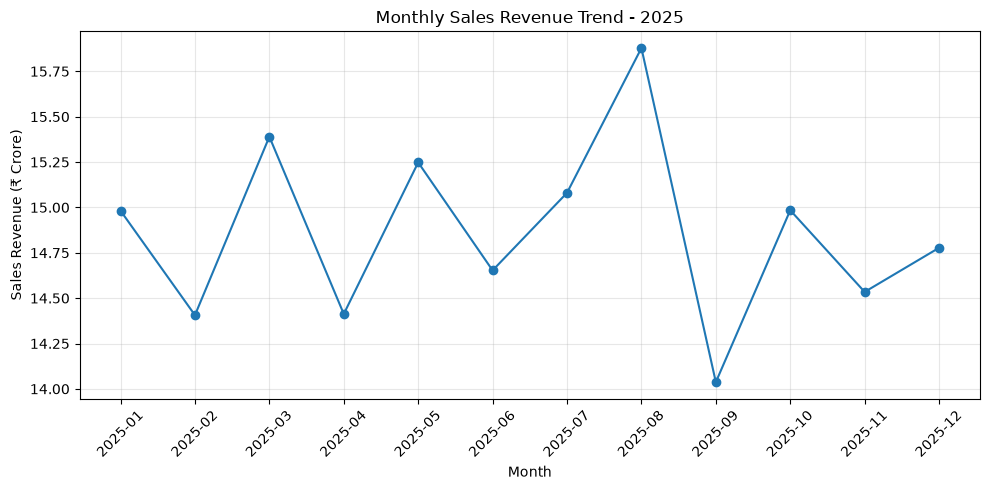

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales["Order_Date"],
    monthly_sales["Sales_Revenue_INR"] / 1_00_00_000,
    marker="o"
)

plt.title("Monthly Sales Revenue Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Sales Revenue (₹ Crore)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# Identify records where stock is below reorder level
inventory_analysis = df.dropna(
    subset=["Stock_On_Hand", "Reorder_Level"]
).copy()

inventory_analysis["Stock_Status"] = np.where(
    inventory_analysis["Stock_On_Hand"] < inventory_analysis["Reorder_Level"],
    "Reorder Required",
    "Stock Sufficient"
)

stock_summary = (
    inventory_analysis["Stock_Status"]
    .value_counts()
    .rename_axis("Stock_Status")
    .reset_index(name="Record_Count")
)

display(stock_summary)

print(
    "Records excluded due to missing stock/reorder values:",
    len(df) - len(inventory_analysis)
)

,Stock_Status,Record_Count
0,Stock Sufficient,24330
1,Reorder Required,10606


Records excluded due to missing stock/reorder values: 64


In [17]:
# Delivery status analysis
delivery_analysis = (
    df["Delivery_Status"]
    .value_counts()
    .rename_axis("Delivery_Status")
    .reset_index(name="Record_Count")
)

delivery_analysis["Percentage"] = (
    delivery_analysis["Record_Count"] / len(df) * 100
).round(2)

display(delivery_analysis)

,Delivery_Status,Record_Count,Percentage
0,On Time,22957,65.59
1,Delayed,6714,19.18
2,In Transit,3864,11.04
3,Cancelled,1465,4.19


In [18]:
# Supplier performance analysis
supplier_analysis = (
    df.groupby("Supplier_Name")
      .agg(
          Records=("Record_ID", "count"),
          Units_Sold=("Units_Sold", "sum"),
          Avg_Lead_Time_Days=("Lead_Time_Days", "mean"),
          Shipping_Cost_INR=("Shipping_Cost_INR", "sum")
      )
      .sort_values("Units_Sold", ascending=False)
      .round(2)
      .reset_index()
)

display(supplier_analysis)

,Supplier_Name,Records,Units_Sold,Avg_Lead_Time_Days,Shipping_Cost_INR
0,Brightline Imports,4409,203817,6.71,1937453.27
1,Metro Wholesale,4430,203210,6.57,1966384.80
2,PrimeSource India,4396,201699,6.70,1959154.17
3,UrbanCart Partners,4361,200147,6.67,1927870.20
4,Northstar Traders,4373,199504,6.63,1939385.06
5,Evergreen Distributors,4478,199221,6.74,1959308.67
6,Apex Retail Supply,4292,196976,6.66,1896374.85
7,BluePeak Supplies,4261,193805,6.76,1910664.66


In [19]:
# Category-wise return analysis
returns_analysis = (
    df.groupby("Category")
      .agg(
          Units_Sold=("Units_Sold", "sum"),
          Returned_Units=("Returned_Units", "sum")
      )
      .reset_index()
)

returns_analysis["Return_Rate_Percent"] = (
    returns_analysis["Returned_Units"]
    / returns_analysis["Units_Sold"].replace(0, np.nan)
    * 100
).round(2)

returns_analysis = returns_analysis.sort_values(
    "Return_Rate_Percent", ascending=False
)

display(returns_analysis)

,Category,Units_Sold,Returned_Units,Return_Rate_Percent
5,Grocery,121341,1080.0,0.89
7,Pet Supplies,63327,563.0,0.89
10,Toys,66340,580.0,0.87
6,Home & Living,447234,3876.0,0.87
1,Electronics,323196,2697.0,0.83
2,Fashion,194381,1622.0,0.83
9,Stationery,65375,534.0,0.82
0,Beauty,125578,1019.0,0.81
4,Garden,63607,487.0,0.77
8,Sports,63684,493.0,0.77


In [20]:
# Demand forecast vs actual sales
forecast_analysis = df.dropna(
    subset=["Demand_Forecast_Units", "Units_Sold"]
).copy()

forecast_analysis["Forecast_Variance"] = (
    forecast_analysis["Units_Sold"]
    - forecast_analysis["Demand_Forecast_Units"]
)

forecast_analysis["Forecast_Status"] = np.select(
    [
        forecast_analysis["Forecast_Variance"] > 0,
        forecast_analysis["Forecast_Variance"] < 0
    ],
    [
        "Sales Above Forecast",
        "Sales Below Forecast"
    ],
    default="Sales Matched Forecast"
)

forecast_summary = (
    forecast_analysis["Forecast_Status"]
    .value_counts()
    .rename_axis("Forecast_Status")
    .reset_index(name="Record_Count")
)

display(forecast_summary)

print(
    "Records included:",
    len(forecast_analysis)
)

,Forecast_Status,Record_Count
0,Sales Below Forecast,17111
1,Sales Above Forecast,13480
2,Sales Matched Forecast,4342


Records included: 34933


In [21]:
# Overall project summary
total_revenue = df["Sales_Revenue_INR"].sum()
total_units_sold = df["Units_Sold"].sum()
total_estimated_profit = df["Estimated_Gross_Profit_INR"].sum()

print("RETAIL INVENTORY & SUPPLY CHAIN ANALYSIS")
print("-" * 45)

print(f"Total Records: {len(df):,}")
print(f"Total Categories: {df['Category'].nunique()}")
print(f"Total Suppliers: {df['Supplier_Name'].nunique()}")
print(f"Total Units Sold: {total_units_sold:,.0f}")
print(f"Total Sales Revenue: ₹{total_revenue:,.2f}")
print(f"Estimated Gross Profit: ₹{total_estimated_profit:,.2f}")

print("\nData Quality")
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Cells:", df.isnull().sum().sum())

RETAIL INVENTORY & SUPPLY CHAIN ANALYSIS
---------------------------------------------
Total Records: 35,000
Total Categories: 11
Total Suppliers: 8
Total Units Sold: 1,598,379
Total Sales Revenue: ₹1,783,830,481.00
Estimated Gross Profit: ₹873,544,471.00

Data Quality
Duplicate Rows: 0
Missing Cells: 307


In [22]:
output_file = "Retail_Inventory_Supply_Chain_Cleaned.csv"

df.drop(
    columns=[
        "Sales_Revenue_INR",
        "Estimated_Gross_Profit_INR",
        "Stock_Status"
    ],
    errors="ignore"
).to_csv(output_file, index=False)

print("Final cleaned CSV updated successfully!")
print("Shape:", df.shape)

Final cleaned CSV updated successfully!
Shape: (35000, 27)


In [1]:
import pandas as pd

file_path = "Retail_Inventory_Supply_Chain_Cleaned.csv"

df = pd.read_csv(file_path)

integer_columns = [
    "Stock_On_Hand",
    "Reorder_Level",
    "Order_Quantity",
    "Units_Sold",
    "Lead_Time_Days",
    "Returned_Units",
    "Demand_Forecast_Units"
]

for col in integer_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce").round().astype("Int64")

df.to_csv(file_path, index=False)

print("CSV numeric formats fixed and file saved!")
print(df[integer_columns].dtypes)

CSV numeric formats fixed and file saved!
Stock_On_Hand            Int64
Reorder_Level            Int64
Order_Quantity           Int64
Units_Sold               Int64
Lead_Time_Days           Int64
Returned_Units           Int64
Demand_Forecast_Units    Int64
dtype: object
